In [47]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [48]:
from crafts_stack.measure import Measurement, np, os, plt

In [49]:
values = range(5)
errors = [0.1, 0.2, 0.3, 0.4, 0.5]

m = Measurement(values, errors)
print("原始 Measurement 对象：")
print(m)

print("\n--- 切片测试 ---")
# 测试切片：获取前三个元素
m_slice = m[:3]
print("m[:3] (切片)：")
print(m_slice)

# 测试索引：获取第二个元素 (索引 1)
m_index = m[1]
print("\nm[1] (索引)：")
print(m_index)

# 测试布尔索引（例如，值大于 30 的元素）
mask = m.value > 2
m_masked = m[mask]
print("\nm[mask] (布尔索引)：")
print(m_masked)

print("\n--- 运算兼容性测试 ---")
# 对切片后的对象进行运算
m_calc = m_slice + 5
print("m[:3] + 5 的结果：")
print(m_calc)

原始 Measurement 对象：
Values (size=5): [0 1 2 3 4]
Errors (size=5): [0.1 0.2 0.3 0.4 0.5]

--- 切片测试 ---
m[:3] (切片)：
Values (size=3): [0 1 2]
Errors (size=3): [0.1 0.2 0.3]

m[1] (索引)：
1.0000 +/- 0.2000

m[mask] (布尔索引)：
Values (size=2): [3 4]
Errors (size=2): [0.4 0.5]

--- 运算兼容性测试 ---
m[:3] + 5 的结果：
Values (size=3): [5 6 7]
Errors (size=3): [0.1 0.2 0.3]


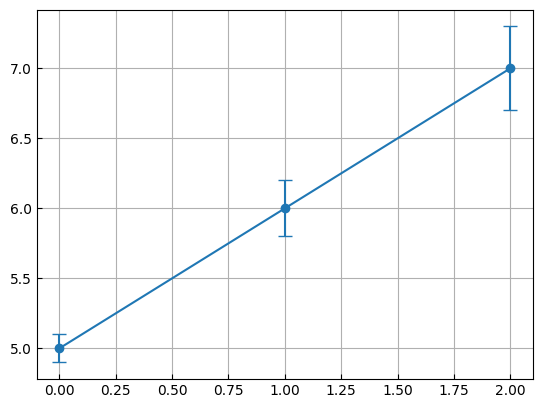

In [50]:
m_calc.plot()

In [51]:
# --- Usage Example ---
file_path = 'test_measurement_data.npz'

# 1. Create and Save
print("--- 1. Create and Save ---")
m1 = Measurement([1.2, 3.4, 5.6], [0.1, 0.2, 0.3])
print("Original Measurement m1:")
print(m1)
m1.save(file_path)

# 2. Load
print("\n--- 2. Load from File ---")
m_loaded = Measurement.load_from_file(file_path)
print("Loaded Measurement m_loaded:")
print(m_loaded)

# 3. Verify
print("\n--- 3. Verification ---")
# Check if loaded data is identical
is_value_match = np.allclose(m1.value, m_loaded.value)
is_error_match = np.allclose(m1.error, m_loaded.error)
print(f"Value arrays match: {is_value_match}")
print(f"Error arrays match: {is_error_match}")

# Clean up the test file
if os.path.exists(file_path):
    os.remove(file_path)
    print(f"\nCleaned up test file: {file_path}")

--- 1. Create and Save ---
Original Measurement m1:
Values (size=3): [1.2 3.4 5.6]
Errors (size=3): [0.1 0.2 0.3]
Measurement data saved to test_measurement_data.npz

--- 2. Load from File ---
Loaded Measurement m_loaded:
Values (size=3): [1.2 3.4 5.6]
Errors (size=3): [0.1 0.2 0.3]

--- 3. Verification ---
Value arrays match: True
Error arrays match: True

Cleaned up test file: test_measurement_data.npz


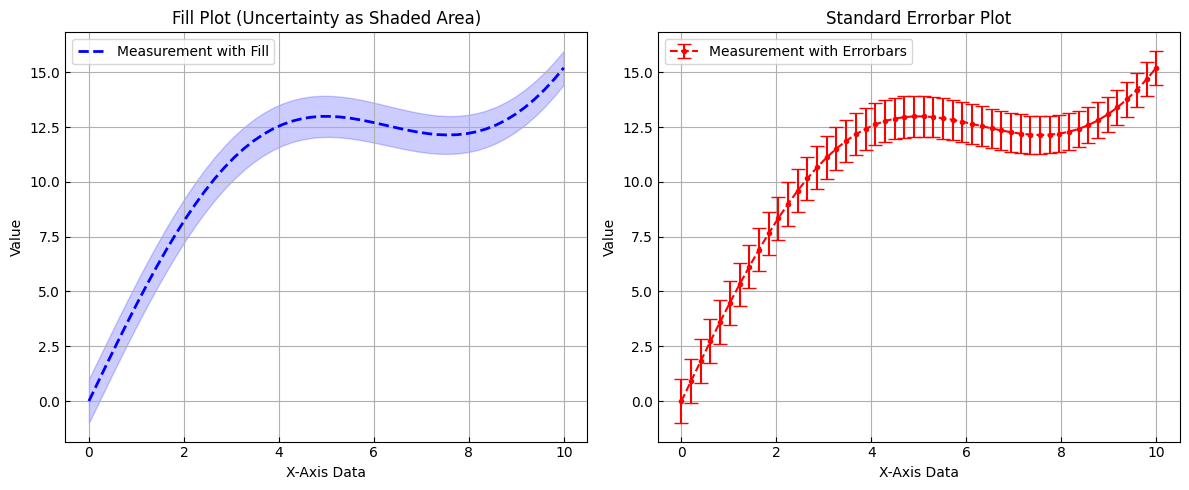

In [52]:
# 模拟数据
x_data = np.linspace(0, 10, 50)
# 模拟一个随 x 增加的中心值
center_values = 2.0 * x_data + 5 * np.sin(x_data / 2)
# 模拟一个随 x 减小的误差
errors = 0.5 + 0.5 * np.cos(x_data / 10)

m_data = Measurement(center_values, errors)

plt.figure(figsize=(12, 5))

# --- 1. Fill Plot Example ---
ax1 = plt.subplot(1, 2, 1)
# 使用 fill_plot 绘制
m_data.fill_plot(
    ax=ax1, 
    x=x_data, 
    label="Measurement with Fill", 
    color='blue', 
    alpha=0.2,
    linewidth=2,
    linestyle='--' # 中心线使用虚线
)
ax1.set_title("Fill Plot (Uncertainty as Shaded Area)")
ax1.set_xlabel("X-Axis Data")
ax1.set_ylabel("Value")

# --- 2. Standard Errorbar Plot for Comparison ---
ax2 = plt.subplot(1, 2, 2)
# 使用原始 plot 绘制 (默认的 errorbar 风格)
m_data.plot(
    ax=ax2, 
    x=x_data, 
    label="Measurement with Errorbars", 
    color='red', 
    fmt='--o',
    ms=3 # Marker size
)
ax2.set_title("Standard Errorbar Plot")
ax2.set_xlabel("X-Axis Data")
ax2.set_ylabel("Value")

plt.tight_layout()
plt.show()

In [53]:
# 信号测量 (Signal Measurement)
Signal_A = Measurement(value=10.0, error=0.5)

# 噪声测量 (Noise Measurement) - 只有它的误差被用作信噪比计算的分母
Noise_B = Measurement(value=2.0, error=0.1) 

# 使用 snr_of_ratio 10.0 / 0.1
# SNR Value: 10.0 / 0.1 = 100.0
# SNR Error: 0.5 / 0.1 = 5.0
snr_result = Signal_A.get_snr(Noise_B)
print("--- Custom SNR Calculation (Signal_A.value / Noise_B.error) ---")
print(f"Signal A: {Signal_A}")
print(f"Noise B: {Noise_B}")
print(f"SNR Result: {snr_result}") 
# Expected: 100.0000 +/- 5.0000

# 数组测试
x = np.array([100, 50, 200])
y = np.array([10, 5, 20])

m_sig = Measurement(x, 0.1*x) # Signal A: Value=[100, 50, 200], Error=[10, 5, 20]
m_noise = Measurement([1, 1, 1], [0.5, 0.2, 0.4]) # Noise B: Error=[0.5, 0.2, 0.4]

snr_array = m_sig.get_snr(m_noise)
print("\n--- Array SNR Calculation ---")
print(f"SNR Array Result: \n{snr_array}")
# Expected Values: [200, 250, 500] (100/0.5, 50/0.2, 200/0.4)
# Expected Errors: [20, 25, 50] (10/0.5, 5/0.2, 20/0.4)

--- Custom SNR Calculation (Signal_A.value / Noise_B.error) ---
Signal A: 10.0000 +/- 0.5000
Noise B: 2.0000 +/- 0.1000
SNR Result: 100.0000 +/- 5.0000

--- Array SNR Calculation ---
SNR Array Result: 
Values (size=3): [200. 250. 500.]
Errors (size=3): [20. 25. 50.]
